# 画像の中の日本語を読み取り (OCR)、文字誤り率で比べる

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/29_vision_language/ocr_ja.ipynb)

NLP クックブック 29-04 ／ 画像と言語

> GPU ランタイム推奨（ランタイム → ランタイムのタイプを変更 → T4 GPU）

画像に写った日本語の文字を読み取りたい。従来型の OCR (Tesseract)、日本語に特化した OCR (manga-ocr)、視覚言語モデル（VLM、Qwen3-VL）を、条件を変えた画像の文字誤り率 (CER) で比べる。

In [1]:
# Tesseract 本体 (Colab には入っている) と日本語 (横書き・縦書き) のモデル、日本語フォント (Noto CJK)
!apt-get install -y -q tesseract-ocr tesseract-ocr-jpn tesseract-ocr-jpn-vert fonts-noto-cjk > /dev/null
!pip install -q pytesseract jiwer manga-ocr

27 枚
基準


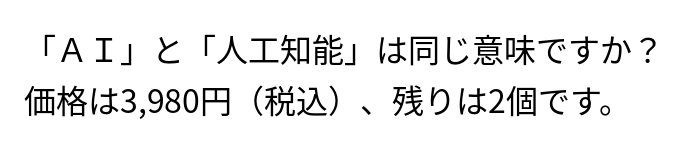

明朝体


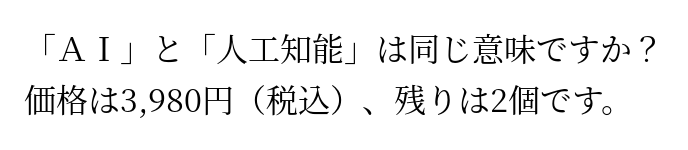

小さい文字


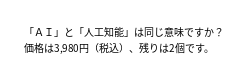

傾き5度


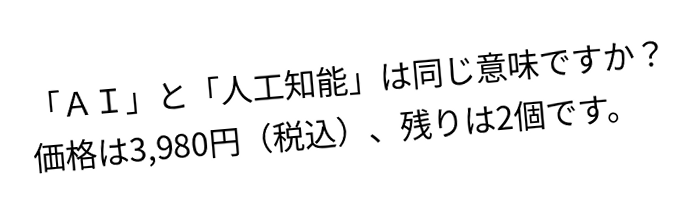

ノイズ


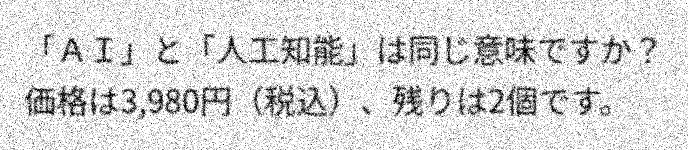

低解像度


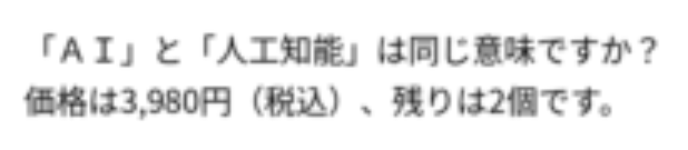

背景の模様


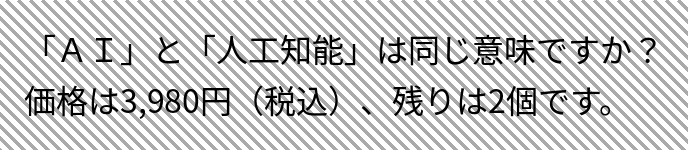

縦書き


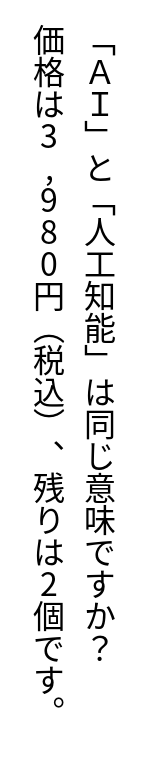

紛らわしい文字


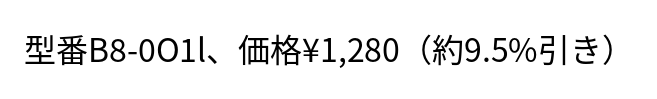

In [2]:
# 正解が分かるように、PIL で日本語の文を描いた画像を自分で作る (条件: フォント、文字の大きさ、傾き、ノイズ、ぼけ、背景の模様、縦書き)
import numpy as np
from PIL import Image, ImageDraw, ImageFilter, ImageFont

SANS = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"    # fonts-noto-cjk のゴシック体
SERIF = "/usr/share/fonts/opentype/noto/NotoSerifCJK-Regular.ttc"  # 明朝体

def render(text, size=32, font=SANS, vertical=False, angle=0, noise=0, scale=1, pattern=False, pad=24):
    f = ImageFont.truetype(font, size)
    lines, step = text.split("\n"), int(size * 1.6)
    if vertical:
        w, h = len(lines) * step + 2 * pad, max(len(l) for l in lines) * int(size * 1.05) + 2 * pad
    else:
        w, h = max(int(f.getlength(l)) for l in lines) + 2 * pad, len(lines) * step + 2 * pad
    img = Image.new("L", (w, h), 255)
    d = ImageDraw.Draw(img)
    if pattern:                                     # 斜めの縞模様の背景
        for x in range(-h, w, 12):
            d.line([(x, 0), (x + h, h)], fill=170, width=3)
    for i, l in enumerate(lines):
        if vertical:                                # 縦書き: 右の列から左へ。vert で括弧や長音記号を縦書き用の字形にする
            d.text((w - pad - (i + 1) * step + (step - size) // 2, pad), l, font=f, fill=0, direction="ttb", features=["vert"])
        else:
            d.text((pad, pad + i * step), l, font=f, fill=0)
    if angle:
        img = img.rotate(angle, expand=True, fillcolor=255, resample=Image.BICUBIC)
    if scale != 1:                                  # 一度縮小してから戻す (解像度の低い画像)
        img = img.resize((int(img.width * scale), int(img.height * scale)), Image.BILINEAR).resize(img.size, Image.BILINEAR)
    if noise:                                       # 少しぼかしてからガウスノイズを足す
        a = np.asarray(img.filter(ImageFilter.GaussianBlur(1)), dtype=float)
        img = Image.fromarray((a + np.random.default_rng(0).normal(0, noise, a.shape)).clip(0, 255).astype("uint8"))
    return img.convert("RGB")

TEXTS = ["クックブック食堂は月曜日が定休日です。\n営業時間は11時から15時までとなります。",
         "ロボットのカメラは工場の入口に設置された。\n二人のエンジニアが力を合わせて調整した。",   # ロ/口、エ/工、ニ/二、カ/力
         "「ＡＩ」と「人工知能」は同じ意味ですか？\n価格は3,980円（税込）、残りは2個です。"]       # 全角・半角、記号
HARD = ["口ロ工エ力カ二ニ夕タ卜ト八ハ",                        # 漢字とカタカナの組 (意味のない並び)
        "森鷗外の旧居の近くに髙橋さんと山﨑さんが住む。",       # 異体字 (鷗、髙、﨑)
        "型番B8-0O1l、価格¥1,280（約9.5%引き）"]               # 英数字と記号 (0/O、1/l)
CONDS = {"基準": {}, "明朝体": {"font": SERIF}, "小さい文字": {"size": 10}, "傾き5度": {"angle": 5},
         "ノイズ": {"noise": 60}, "低解像度": {"scale": 0.3}, "背景の模様": {"pattern": True}, "縦書き": {"vertical": True}}
data = [(c, t, render(t, **kw)) for c, kw in CONDS.items() for t in TEXTS]
data += [("紛らわしい文字", t, render(t)) for t in HARD]
print(len(data), "枚")
for c, t, img in data[2::3]:
    print(c)
    display(img)

In [3]:
# (1) 従来型の OCR: Tesseract。横書きは jpn、縦書きは jpn_vert のモデルを使う
import time
import pytesseract

def tesseract(img, vertical=False):
    if vertical:
        return pytesseract.image_to_string(img, lang="jpn_vert", config="--psm 5")   # psm 5: 縦書きの 1 ブロック
    return pytesseract.image_to_string(img, lang="jpn", config="--psm 6")            # psm 6: 横書きの 1 ブロック

results, seconds = {}, {}
t = time.time()
results["Tesseract"] = [tesseract(img, c == "縦書き") for c, _, img in data]
seconds["Tesseract"] = (time.time() - t) / len(data)
for i in [0, 12, 21]:     # 基準、ノイズ、縦書き
    print(repr(results["Tesseract"][i]))

'クックブック食堂は月曜日が定休日です。\n営業時間は11時から15時までとなります。\n'
''
'クッ ク ブ ッ ク 食 堂 は 月 曜日 が 定休 日 で す 。\n営業 時 間 は 11 時 か ら 15 時 まで と な り ま す 。\n'


In [4]:
# (2) 日本語に特化した OCR: manga-ocr (漫画の吹き出しなど、短い文字のまとまりを 1 回で読む。縦書きも横書きもそのまま読める)
from manga_ocr import MangaOcr

mocr = MangaOcr()   # 初回はモデル (kha-white/manga-ocr-base, 約 450MB) をダウンロードする
t = time.time()
results["manga-ocr"] = [mocr(img) for _, _, img in data]
seconds["manga-ocr"] = (time.time() - t) / len(data)
print(repr(results["manga-ocr"][0]))

'クックブック食堂は月曜日が定休日です。営業時間は１１時から５時までとなります。'


In [5]:
# (3) 視覚言語モデル (VLM) に「書き写して」と頼む: Qwen3-VL-4B-Instruct (Apache-2.0)
# 初回はモデル (約 9GB) のダウンロードに数分かかる。float16 で GPU メモリを約 9GB 使うので T4 (16GB) に載る
import torch
from transformers import AutoModelForImageTextToText, AutoProcessor

name = "Qwen/Qwen3-VL-4B-Instruct"
BF16 = torch.cuda.get_device_capability()[0] >= 8      # bfloat16 は Ampere (A100, L4) 以降。T4 では float16 を使う
processor = AutoProcessor.from_pretrained(name)
model = AutoModelForImageTextToText.from_pretrained(name, dtype=torch.bfloat16 if BF16 else torch.float16, device_map="cuda").eval()

def vlm_ocr(img, prompt="画像の中の文字を、改行も含めてそのまま書き写してください。書き写した文字以外は出力しないでください。"):
    messages = [{"role": "user", "content": [{"type": "image", "image": img}, {"type": "text", "text": prompt}]}]
    inputs = processor.apply_chat_template(messages, tokenize=True, add_generation_prompt=True,
                                           return_dict=True, return_tensors="pt").to(model.device)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=200, do_sample=False)
    return processor.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)

t = time.time()
results["Qwen3-VL"] = [vlm_ocr(img) for _, _, img in data]
seconds["Qwen3-VL"] = (time.time() - t) / len(data)
for i in [0, 2]:
    print(repr(results["Qwen3-VL"][i]))
print(f"GPU メモリの最大使用量 (manga-ocr を含む): {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")

'クックブック食堂は月曜日が定休日です。\n営業時間は11時から15時までとなります。'
'「A I」と「人工知能」は同じ意味ですか？\n価格は3,980円（税込）、残りは2個です。'
GPU メモリの最大使用量 (manga-ocr を含む): 9.4 GB


In [6]:
# 正規化 (NFKC で全角・半角をそろえ、空白と改行を除く) してから、条件ごとに文字誤り率 (CER) を計算する
import unicodedata
import jiwer
import pandas as pd

def normalize(s):
    return "".join(unicodedata.normalize("NFKC", s).split())

rows = []
for method, outs in results.items():
    for (c, ref, _), hyp in zip(data, outs):
        rows.append({"条件": c, "手法": method, "CER": jiwer.cer(normalize(ref), normalize(hyp) or " "),
                     "CER (正規化なし)": jiwer.cer(ref, hyp.strip() or " ")})
df = pd.DataFrame(rows)
table = df.pivot_table(index="条件", columns="手法", values="CER", sort=False)
table.loc["平均"] = table.mean()
print(table.round(3).to_string())
print("\n正規化しない場合の平均 CER:", df.groupby("手法")["CER (正規化なし)"].mean().round(3).to_dict())
print("1 枚あたりの秒数:", {k: round(v, 2) for k, v in seconds.items()})

手法       Tesseract  manga-ocr  Qwen3-VL
条件                                     
基準           0.008      0.088     0.000
明朝体          0.008      0.081     0.000
小さい文字        0.178      0.274     0.000
傾き5度         0.098      0.160     0.000
ノイズ          1.000      0.178     0.000
低解像度         0.016      0.138     0.000
背景の模様        0.968      0.283     0.000
縦書き          0.008      0.080     0.000
紛らわしい文字      0.236      0.431     0.173
平均           0.280      0.190     0.019

正規化しない場合の平均 CER: {'Qwen3-VL': 0.037, 'Tesseract': 0.397, 'manga-ocr': 0.253}
1 枚あたりの秒数: {'Tesseract': 0.18, 'manga-ocr': 0.17, 'Qwen3-VL': 1.17}


In [7]:
# どんな誤りが多いか: 文字の置換 (正解 → 出力) を数え、誤りの例を並べる
from collections import Counter

def substitutions(ref, hyp):
    ref, hyp = normalize(ref), normalize(hyp)
    out = jiwer.process_characters(ref, hyp or " ")
    pairs = []
    for ch in out.alignments[0]:
        if ch.type == "substitute":
            pairs += [f"{ref[ch.ref_start_idx + k]}→{hyp[ch.hyp_start_idx + k]}" for k in range(ch.ref_end_idx - ch.ref_start_idx)]
    return pairs

for method, outs in results.items():
    pairs = Counter(p for (_, ref, _), hyp in zip(data, outs) for p in substitutions(ref, hyp))
    print(method, pairs.most_common(12))

for i in [8, 23, 25, 26]:     # 小さい文字、縦書き、紛らわしい文字 (異体字、英数字)
    c, ref, _ = data[i]
    print(f"\n[{c}] 正解: {ref!r}")
    for method, outs in results.items():
        print(f"  {method:10s} {outs[i].strip()!r}")

Tesseract [('I→T', 4), ('ク→N', 3), ('「→T', 2), ('ッ→S', 2), ('日→N', 2), ('「→N', 2), ('食→信', 1), ('堂→登', 1), ('場→坦', 1), ('調→六', 1), ('I→エ', 1), ('意→斉', 1)]
manga-ocr [(',→0', 5), ('調→き', 3), ('に→は', 2), ('能→識', 2), ('9→0', 2), ('2→国', 2), ('か→が', 2), ('?→、', 2), ('整→ま', 2), ('力→大', 2), ('整→離', 1), ('I→コ', 1)]
Qwen3-VL [('力→カ', 1), ('二→ニ', 1), ('夕→タ', 1), ('卜→ト', 1), ('八→ハ', 1), ('髙→高', 1), ('﨑→崎', 1), ('O→0', 1)]

[小さい文字] 正解: '「ＡＩ」と「人工知能」は同じ意味ですか？\n価格は3,980円（税込）、残りは2個です。'
  Tesseract  'TATエ」と「人知能」は同じ斉味ですか2\n価は3980円 (入) 、残りは2但です。'
  manga-ocr  '「ＡＤと「人式胞」は同じ意味ですが？価格は８００円（税込、利用）は個にす。'
  Qwen3-VL   '「ＡＩ」と「人工知能」は同じ意味ですか？\n価格は3,980円（税込）、残りは2個です。'

[縦書き] 正解: '「ＡＩ」と「人工知能」は同じ意味ですか？\n価格は3,980円（税込）、残りは2個です。'
  Tesseract  '「AI」 と 「 人 工 知 能 」 は 同じ 意味 で すか ?\n価格 は 3,.980 円 (税込 )、 残 り は 2 個 で す 。'
  manga-ocr  '「Ａさと「入工知能」は同じ意味ですか？価格は３，９００円（税込、残りは２５個です。'
  Qwen3-VL   '「AＩ」と「人工知能」は同じ意味ですか？\n価格は3,980円(税込)、残りは2個です。'

[紛らわしい文字] 正解: '森鷗外の旧居の近くに髙橋さんと山﨑さんが住む。'
  Tesseract  '森暗外の旧居の近くに高橋さんと山崎さんが住む。'
  manga-oc

In [8]:
# 縦書きの画像を横書きのモデル (jpn) で読むと、行を横に読んでしまい、読み順が崩れる
c, ref, img = data[21]
print(repr(pytesseract.image_to_string(img, lang="jpn", config="--psm 6")[:60]))

'営 ク\n業 ツ\n時 ク\n間 ブ\nは ッ\n1 ク\n1 食\n時 堂\nか は\nら 月\n1 曜\n5 日\n時 が\nま 定\nで 休\n'


In [9]:
# VLM は書かれていない文字を補ったり、誤字を直したりすることがある。正解とは「画像に書かれているとおり」の文字列
def masked(text, start, n, size=32):     # text[start:start+n] を白い四角で消す
    img = render(text, size=size)
    f = ImageFont.truetype(SANS, size)
    x0, x1 = 24 + f.getlength(text[:start]), 24 + f.getlength(text[:start + n])
    ImageDraw.Draw(img).rectangle([x0, 20, x1, 24 + size * 1.3], fill="white")
    return img

demo = {"誤字 (ごさいました)": render("本日はご来店いただき、誠にありがとうごさいました。"),
        "誤字 (シュミレーション)": render("明日は避難訓練のシュミレーションを行います。"),
        "重複 (からから)": render("会議は午後3時からからです。"),
        "1 字を消す (回)": masked("急がば回れ、急いては事を仕損じる。", 3, 1)}
for k, img in demo.items():
    print(f"[{k}]\n  Tesseract {tesseract(img).strip()!r}\n  manga-ocr {mocr(img)!r}\n  Qwen3-VL  {vlm_ocr(img)!r}")

[誤字 (ごさいました)]
  Tesseract '本日はご来店いただき、誠にありがとうごさいました。'
  manga-ocr '本日は来店いただき、誠にありがとうございました。'
  Qwen3-VL  '本日はご来店いただき、誠にありがとうございました。'
[誤字 (シュミレーション)]
  Tesseract '明日は避難訓練のシュミレーションを行います。'
  manga-ocr '明日は選転職のシュミレーションを伺います。'
  Qwen3-VL  '明日は避難訓練のシミュレーションを行います。'
[重複 (からから)]
  Tesseract '会議は午後3時からからです。'
  manga-ocr '会議は午後３時からからです。'
  Qwen3-VL  '会議は午後3時からからです。'
[1 字を消す (回)]
  Tesseract '急がば れ、急いては事を仕損じる。'
  manga-ocr '急がば、れ、急いでは事を仕損しる。'
  Qwen3-VL  '急がば\u3000れ、急いては事を仕損じる。'


- 表の値は、条件ごとに 1 枚ずつ計算した CER の平均。評価指標と統計的検定の章の「音声認識や OCR の誤り率 (WER / CER) を計算する」のように jiwer に文の一覧をまとめて渡すと、全体の文字数で割った CER になり、値が少し違う。1 条件は 3 枚（約 70 字）しかないので、1 字の誤りで CER が約 0.014 動く（基準の 0.008 と低解像度の 0.016 の差は 1 字ぶん）。小さな差で手法の優劣を決めない。
- 正規化の影響: Tesseract は縦書きで字の間に空白を入れ、括弧を半角にする。manga-ocr はライブラリの後処理で空白を除き、英数字を全角にする。Qwen3-VL も「A I」のように空白を入れる。正規化しないと平均 CER は Tesseract 0.397、manga-ocr 0.253、Qwen3-VL 0.037 で、NFKC と空白の除去をすると 0.280、0.190、0.019 になった。ここでは記号の誤りも見たいので句読点は残した。正規化の方針で値が変わるので、そろえて明記する。
- 従来型の OCR は、レイアウト解析（ブロックや行を見つける。`--psm` で指定する）と、行ごとの文字認識（Tesseract 4 以降は LSTM）を順に行う。内部で二値化（大津の方法）してから文字を探すので（公式ドキュメント「Improving the quality of the output」）、背景の模様（縞を N や S と読んだ）やノイズ（空の出力）で読めなくなり、小さい文字や傾きでも誤りが増えた。VLM は画像全体を見て、読み順も含めて文字列を生成する。そのぶん重く、1 枚あたり Tesseract は 0.18 秒 (CPU)、Qwen3-VL は 1.17 秒 (GPU) かかった（検証に使った 32 コアの CPU と GPU での値で、実行ごとに 2〜3 割変わる。Colab の T4 では確かめていない）。
- 誤りの種類（上の出力より）。似た字形: Tesseract は「ＡＩ」の I を T やエと読み、堂→登、意→斉と取り違えた。Qwen3-VL は意味のない並びの「力カ二ニ夕タ卜ト八ハ」で、漢字の力・二・夕・卜・八をカタカナにした（口ロ工エは区別できた）。記号: Tesseract は ¥ をバックスラッシュ (`\`) に、「9.5%」を「9.59%」に、「3,980」を「3,.980」や「3980」にした。異体字: 髙→高、﨑→崎は Tesseract と Qwen3-VL の両方が常用の字形に置き換えた（鷗は Qwen3-VL だけが正しく、Tesseract は「暗」）。NFKC の正規化では、これらは同じ字にならない。
- 縦書きは、Tesseract では縦書き用のモデル `jpn_vert` と `--psm 5` を指定すると読み順も正しく読めた。横書きのモデル `jpn` で読むと、2 列を横に並べて読んでしまう（「営 ク / 業 ツ ...」）。manga-ocr と Qwen3-VL は、指定しなくても縦書きを右の列から読んだ。
- VLM は、書かれていない文字をもっともらしく直すことがある。誤字の「ごさいました」を「ございました」に、「シュミレーション」を「シミュレーション」に直して出力した（Tesseract は書かれたとおり。manga-ocr も「ございました」に直した）。一方、「からから」の重複や、消した「回」は補わなかったので、いつ直すかは予測しにくい。誤字の検出や史料の翻刻のように、書かれたとおりに読みたい用途では、この書き換えが誤りになる。manga-ocr（kha-white/manga-ocr-base、Apache-2.0）は漫画の吹き出しを主な対象とするモデル。入力を 224×224 に縮小する (preprocessor_config) ので、横に長い 2 行の画像は不利だと考えられ、「人工知能」を「人工知識」と読むような、もっともらしい別の語を出す誤りが目立った。
- この結果は、1 種類のフォントで描いた短い文の合成画像に限ったもの。Qwen3-VL の CER がほぼ 0 でも、VLM が完璧に読めるということではない。段組み、表、長いページ、手書き、写真の中の文字は試していない。長いページでは、この `max_new_tokens=200` だと出力が途中で切れる。対象と同じ種類の画像を集めて正解を付け、同じ方法で CER を測ってから選ぶ。PDF に文字のデータがあるなら、データの収集と入出力の章の「PDF からテキストを抽出する (PyMuPDF)」のように抽出するほうが正確で速い（そのレシピの注意書きにある PyMuPDF の `get_textpage_ocr()` は、中で Tesseract を呼び出す）。
- 数値はすべて float16 で実行した値。Qwen3-VL-4B-Instruct (Apache-2.0) のモデルカードは、OCR が 32 言語に対応し、ぼけや傾きに強いとしている。GPU メモリの最大使用量は 9.4GB（manga-ocr のモデルも GPU に載せたままの値）。bfloat16 で実行したときも、CER の表、出力、メモリの使用量は同じだった。apt の `tesseract-ocr-jpn` は tessdata_fast（速度重視の整数版モデル）で、精度を優先する tessdata_best も公開されている（ここでは比べていない）。